In [31]:
import pandas as pd
import numpy as np
pd.options.display.max_columns = 100
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OrdinalEncoder
from IPython.display import display


In [32]:
tips = sns.load_dataset('tips')
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [33]:
tips.dropna(inplace = True)

In [34]:
tips.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='str')

In [35]:
tips.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


# Data Prepocessing and Scaling

Clustering algorithms group data based on how close points are to one another. Different data types need different ways to measure this distance:

* Numerical data uses Euclidean distance, which measures the straight-line distance between points. This method works best when the numbers are scaled.
* Categorical data uses Hamming distance, which counts how many values are different. This approach works directly with the original strings.
* Mixed data uses Gower distance, which combines both methods to handle numbers and categories together.

Here, we separate our numerical and categorical data into different dataframes. This way, we can use the right algorithms for each type later on.

In [36]:
numerical_features = ['total_bill', 'tip', 'size']
categorical_features = ['sex', 'smoker', 'day', 'time']

tips_num = tips[numerical_features].copy()
tips_cat = tips[categorical_features].copy()

StandardScaler forces all numerical columns to have a mean of 0 and a standard deviation of 1, ensuring every feature has an equal vote in the K-Means algorithm.

In [37]:
scaler = StandardScaler()

tips_num_scaled = pd.DataFrame(
    scaler.fit_transform(tips_num), 
    columns=tips_num.columns, 
    index=tips_num.index
)

In [38]:
tips_num_scaled.head()

,total_bill,tip,size
0,-0.314711,-1.439947,-0.600193
1,-1.063235,-0.969205,0.453383
2,0.137780,0.363356,0.453383
3,0.438315,0.225754,-0.600193
4,0.540745,0.443020,1.506958


In [39]:
tips_mixed = pd.concat([tips_num_scaled, tips_cat], axis=1)

#### **Task 1**

# Clusters



More clusters here: https://scikit-learn.org/stable/modules/clustering.html


In [40]:
clustering_leaderboard = pd.DataFrame()

## KMeans

https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html

K-Means is the industry standard for numerical clustering. It works by dropping random "centroids" (centre points) into our data space and grouping data points to whichever centroid is physically closest using straight-line Euclidean distance.

K-Means only works with data that has continuous numerical values.

In [41]:
from sklearn.cluster import KMeans

* n_init - K-Means will drop starting centroids 10 separate times and keep the best mathematical result.

In [42]:
km = KMeans(n_clusters = 8, n_init = 10, random_state=42)

# default n_clusters = 8

.fit_predict() calculates the centroids and assigns every row to a cluster number.

In [43]:
kmeans_labels = km.fit_predict(tips_num_scaled)

In [44]:
kmeans_labels

array([1, 1, 2, 3, 5, 4, 1, 5, 1, 3, 1, 4, 1, 5, 3, 3, 1, 2, 2, 2, 3, 3,
       1, 7, 3, 5, 1, 1, 3, 3, 1, 5, 3, 5, 3, 2, 2, 2, 2, 4, 2, 1, 3, 1,
       4, 3, 3, 4, 6, 3, 1, 1, 4, 1, 4, 3, 5, 6, 1, 7, 3, 1, 1, 5, 2, 2,
       1, 1, 1, 1, 1, 2, 6, 3, 1, 1, 3, 5, 3, 3, 3, 3, 1, 6, 1, 4, 1, 3,
       3, 3, 6, 3, 1, 3, 3, 4, 6, 1, 3, 1, 1, 3, 6, 3, 3, 1, 3, 3, 3, 3,
       3, 1, 4, 6, 2, 3, 4, 1, 1, 5, 1, 1, 1, 1, 1, 0, 1, 1, 1, 2, 1, 3,
       1, 1, 3, 1, 1, 1, 1, 1, 3, 0, 0, 0, 1, 1, 2, 1, 1, 1, 1, 1, 2, 5,
       5, 0, 0, 5, 1, 5, 5, 1, 2, 1, 3, 2, 1, 4, 1, 1, 7, 3, 3, 6, 3, 6,
       1, 1, 3, 6, 4, 3, 4, 4, 6, 0, 2, 5, 2, 2, 1, 3, 6, 1, 3, 1, 1, 4,
       1, 1, 2, 1, 1, 1, 5, 2, 2, 5, 6, 1, 6, 4, 7, 1, 4, 1, 5, 1, 1, 5,
       1, 3, 1, 2, 1, 1, 1, 5, 1, 3, 5, 2, 3, 1, 3, 1, 1, 6, 4, 4, 6, 6,
       1, 3], dtype=int32)

In [45]:
tips['kmeans_clusters_n8'] = kmeans_labels

In [46]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size,kmeans_clusters_n8
0,16.99,1.01,Female,No,Sun,Dinner,2,1
1,10.34,1.66,Male,No,Sun,Dinner,3,1
2,21.01,3.50,Male,No,Sun,Dinner,3,2
3,23.68,3.31,Male,No,Sun,Dinner,2,3
4,24.59,3.61,Female,No,Sun,Dinner,4,5


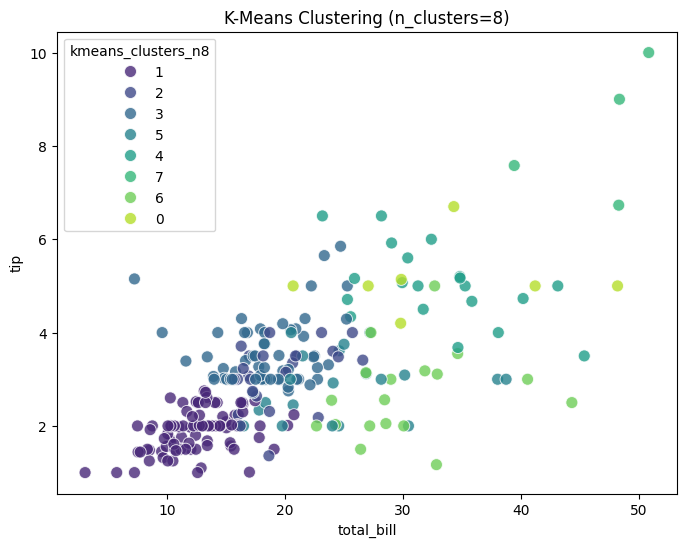

In [47]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=tips, 
    x='total_bill', 
    y='tip', 
    hue=tips['kmeans_clusters_n8'].astype(str),
    palette='viridis',
    s=75,  # Increase marker size for visibility
    alpha=0.8
)
plt.title("K-Means Clustering (n_clusters=8)")
plt.show()

### Evaluation metrics

In [48]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

In supervised learning, we use actual labels, or "ground truth," to check our predictions. In unsupervised clustering, there is no answer key. Instead, we judge the models based only on mathematical geometry. Good clusters have these qualities:

1. **Dense** - Points inside the same cluster should be very close together (Low Intra-cluster variance).
2. **Separated** - Different clusters should be very far apart (High Inter-cluster variance).

The metrics below assume the data is in Euclidean, or straight-line, space. They strongly favour K-Means and will not work if we use raw categorical strings.

### Silhouette score

This measures how far a point is from its own cluster centre, relative to how far it is from the next closest cluster centre.

The values range from -1.0 to 1.0.

* 1.0 = Perfectly separated.
* 0.0 = Overlapping clusters (points are on the boundary).
* -1.0 = Misclassified (points are closer to a neighbouring cluster than their own).

In [49]:
silhouette = silhouette_score(tips_num_scaled, kmeans_labels)
silhouette

# Higher is better, max 1

0.4098537710838614

A score of ~0.40 indicates overlapping clusters. Our n=8 choice was likely too high.

### Calinski-Harabasz score

This metric measures how much the variance between clusters compares to the variance within each cluster.

This metric finds the spatial mean, or centroid, of the data. Because of this, you should not use it with categorical data, since you cannot calculate the mean of values like "Thursday" and "Friday".

The values range from 0 to infinity, and higher scores are always better. It also runs much faster than the Silhouette metric.

In [50]:
calinski = calinski_harabasz_score(tips_num_scaled, kmeans_labels)
calinski

# Higher is better

155.97215801758335

This raw number is meaningless on its own, it is only useful when comparing different models side-by-side.

### Davies-Bouldin score

It compares each cluster to its most similar neighbour. It looks at how spread out the clusters are inside (within-cluster scatter) and compares this to the distance between their centres.

Just like Calinski-Harabasz, Davies-Bouldin requires the physical spatial centre (centroid) of the clusters to measure scatter. Therefore, it is mathematically invalid for categorical data.

The lowest possible value is 0, which means perfect separation. In this case, a lower value is always better.

In [51]:
davies_bouldin = davies_bouldin_score(tips_num_scaled, kmeans_labels)
davies_bouldin

# Lower is better, min 0

0.9499446837556763

A score of ~0.95 is relatively high (bad), further indicating that splitting this small dataset into 8 clusters resulted in overlapping boundaries.

In [52]:
def log_and_display_clustering_metrics(leaderboard_df, model_name, X_data, labels, data_type='numerical'):

    if data_type == 'categorical':
        encoder = OrdinalEncoder()
        X_encoded = encoder.fit_transform(X_data)
        
        silhouette = round(silhouette_score(X_encoded, labels, metric='hamming'), 4)

        calinski = 'N/A'
        davies_bouldin = 'N/A'
    else:
        silhouette = round(silhouette_score(X_data, labels), 4)
        calinski = round(calinski_harabasz_score(X_data, labels), 4)
        davies_bouldin = round(davies_bouldin_score(X_data, labels), 4)
        
    new_row = pd.DataFrame({
            'Model': [model_name],
            'Silhouette (higher=better,max 1)': [silhouette],
            'Calinski-Harabasz (higher=better)': [calinski],
            'Davies-Bouldin (Lower is better,min 0)': [davies_bouldin]
        })
        
    if leaderboard_df is None or leaderboard_df.empty:
        updated_leaderboard = new_row
    else:
        updated_leaderboard = pd.concat([leaderboard_df, new_row], ignore_index=True)
        
    display(updated_leaderboard)
    
    return updated_leaderboard

In [53]:
# Log our baseline K-Means model (n=8) to the leaderboard
# Notice we pass the 'tips_num_scaled' data and explicitly use the default 'numerical' data type

clustering_leaderboard = log_and_display_clustering_metrics(
    clustering_leaderboard, 
    'K-Means n=8', 
    tips_num_scaled, 
    kmeans_labels
)

,Model,"Silhouette (higher=better,max 1)",Calinski-Harabasz (higher=better),"Davies-Bouldin (Lower is better,min 0)"
0,K-Means n=8,0.4099,155.9722,0.9499


### The Elbow Method (Finding the optimal k)

To determine how many clusters we need, we use a metric called Inertia.

* Inertia is the sum of squared distances from each data point to its assigned cluster centre.
* Inertia shows how tight the clusters are. High inertia means the clusters are loose and spread out. Low inertia means the clusters are close together and dense.
* If you set k to the total number of rows in your dataset, inertia drops to zero because each row gets its own cluster. But this doesn't help in real business situations. Instead, we look for the 'Elbow'—the point where adding another cluster no longer gives a big drop in inertia. This is where we start to see diminishing returns.

In [54]:
tips_num_scaled.columns

Index(['total_bill', 'tip', 'size'], dtype='str')

In [55]:
inertia = []

for k in range(1, 11):
    kmeans_model = KMeans(n_clusters=k, n_init = 10, random_state=42)
    kmeans_model.fit(tips_num_scaled)
    inertia.append(kmeans_model.inertia_)


Text(0, 0.5, 'Inertia (Sum of Squared Errors)')

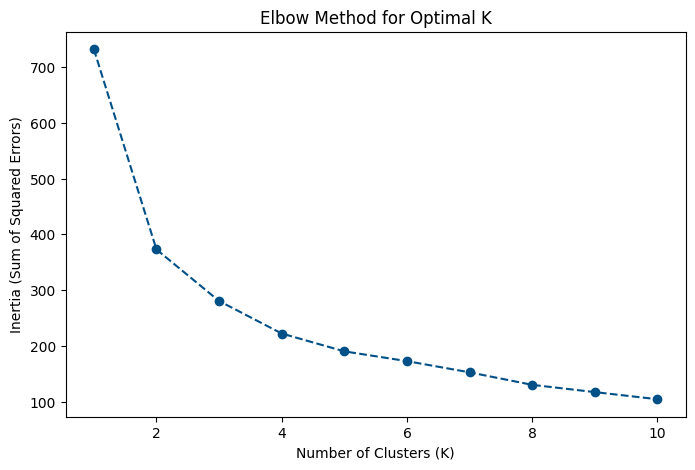

In [56]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker='o', linestyle='--', color='#005088')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (Sum of Squared Errors)')

The Elbow Method points to a clear bend at K=3. Adding more clusters after 3 barely reduces inertia, so the algorithm starts splitting groups that are already tightly packed.

### K = 3

In [57]:
km_3 = KMeans(n_clusters = 3, n_init = 10, random_state=42)
kmeans_labels = km_3.fit_predict(tips_num_scaled)

In [58]:
clustering_leaderboard = log_and_display_clustering_metrics(
    clustering_leaderboard, 
    'K-Means n=3', 
    tips_num_scaled, 
    kmeans_labels
)

,Model,"Silhouette (higher=better,max 1)",Calinski-Harabasz (higher=better),"Davies-Bouldin (Lower is better,min 0)"
0,K-Means n=8,0.4099,155.9722,0.9499
1,K-Means n=3,0.3549,194.0148,1.0416


* The Calinski-Harabasz score increased from 155 to 194. This metric looks at the ratio of variance between clusters to variance within clusters. This suggests that n=3 yields a more stable, generalizable model.
* On the downside, the Silhouette score dropped from 0.40 to 0.35, and the Davies-Bouldin score worsened, rising from 0.94 to 1.04. Both metrics strongly penalise overlap at the edges.

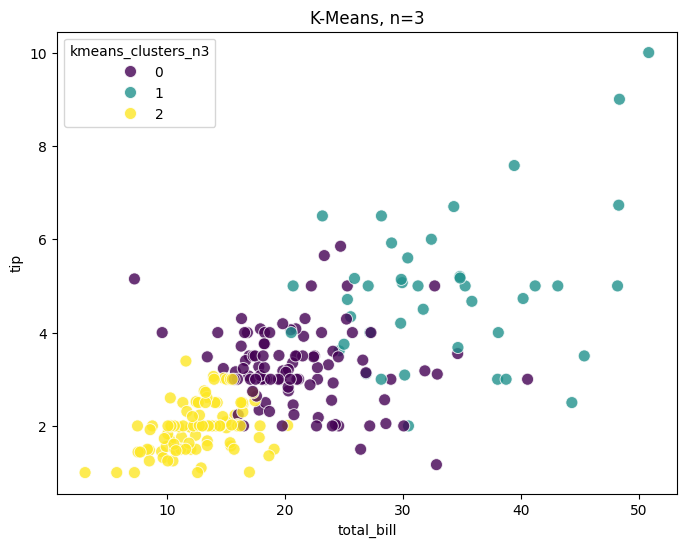

In [59]:
tips['kmeans_clusters_n3'] = kmeans_labels

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=tips, 
    x='total_bill', 
    y='tip', 
    hue='kmeans_clusters_n3', 
    palette='viridis',
    s=75, alpha=0.8
)
plt.title("K-Means, n=3")
plt.show()

* The Yellow Cluster - Low total bill, low tip (Budget diners).

* The Purple Cluster - Average total bill, average tip (Standard diners).

* The Teal Cluster - High total bill, high tip (Large diners).

#### **Task 2**

## K-Modes

In [60]:
from kmodes.kmodes import KModes

We’re no longer working in Euclidean space. For this model, we’re only using the tips_cat features: Sex, Smoker, Day, and Time.

* K-Modes uses Hamming Distance, which doesn’t measure physical distance. Instead, it just counts mismatches. For example, if both data points are labelled "Dinner," the distance is 0. If one is "Lunch" and the other is "Dinner," the distance is 1.
* For initialisation, K-Means uses random points (random_state), but in K-Modes, random starts can be risky since the space is discrete. That’s why we use init='Cao'. It looks at how often each category appears in the data and sets the starting "modes" (centres) on the most common overlaps. This saves computation and helps avoid poor local minima.

In [61]:
# init='Cao' forces the algorithm to start on highly frequent categorical overlaps
kmodes = KModes(n_clusters=3, init='Cao', n_init=5, verbose=0)

In [62]:
kmodes_labels = kmodes.fit_predict(tips_cat)

In [63]:
clustering_leaderboard = log_and_display_clustering_metrics(
    clustering_leaderboard, 
    'K-Modes n=3', 
    tips_cat, 
    kmodes_labels, 
    data_type='categorical'
)

,Model,"Silhouette (higher=better,max 1)",Calinski-Harabasz (higher=better),"Davies-Bouldin (Lower is better,min 0)"
0,K-Means n=8,0.4099,155.9722,0.9499
1,K-Means n=3,0.3549,194.0148,1.0416
2,K-Modes n=3,0.4021,N/A,N/A


In [64]:
tips['KModes_Cluster'] = kmodes_labels

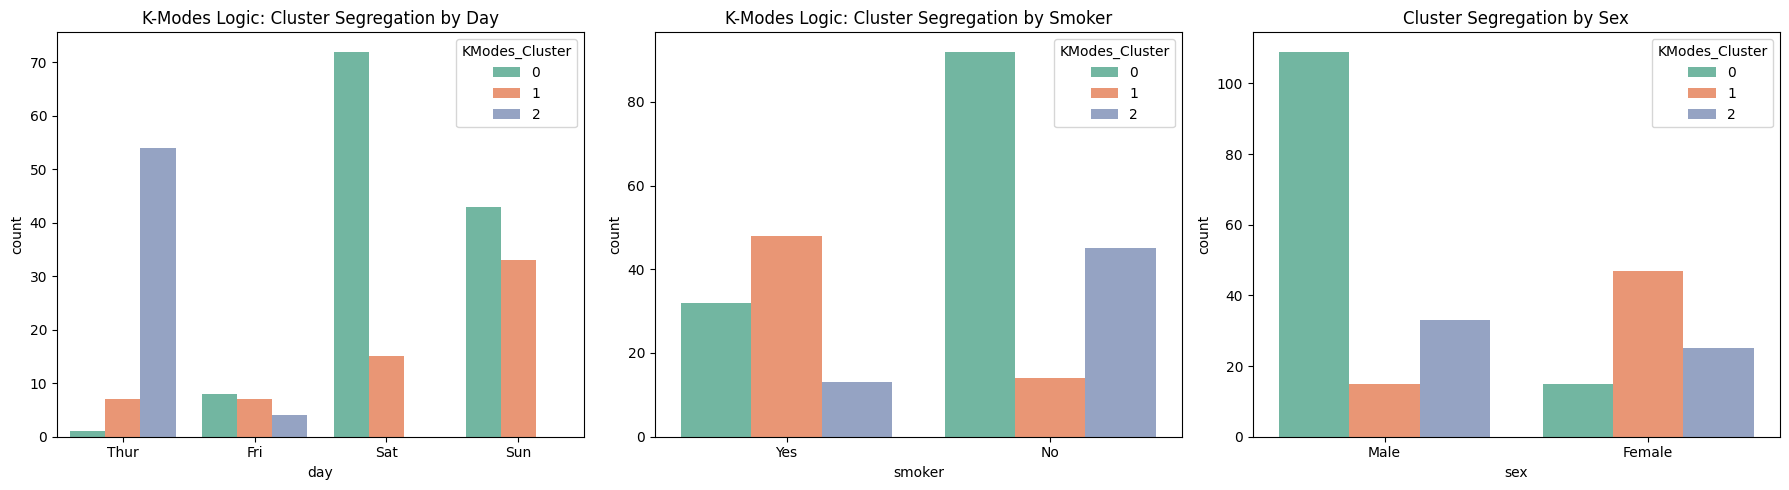

In [65]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(data=tips, x='day', hue='KModes_Cluster', palette='Set2', ax=axes[0])
axes[0].set_title("K-Modes Logic: Cluster Segregation by Day")

sns.countplot(data=tips, x='smoker', hue='KModes_Cluster', palette='Set2', ax=axes[1])
axes[1].set_title("K-Modes Logic: Cluster Segregation by Smoker")

sns.countplot(data=tips, x='sex', hue='KModes_Cluster', palette='Set2', ax=axes[2])
axes[2].set_title("Cluster Segregation by Sex")

plt.tight_layout()
plt.show()

We want to find the mode, or the tallest bar, for each cluster within each category.

If one cluster stands out in a certain category, like Cluster 0 making up 90% of the 'Saturday' bar, it means the algorithm sees 'Saturday' as a key trait for that customer group.

#### **Task 3**

## K-Prototypes (mixed data)

K-Prototypes works by measuring the data in two ways at the same time:

1. It uses Euclidean distance for the columns with continuous values.
2. It uses Hamming distance, which counts mismatches, for categorical columns.
3. The algorithm combines both scores to find the actual centre point.

The algorithm cannot guess which columns are categorical. We need to tell it the index positions so it knows when to change how it measures.

In [66]:
from kmodes.kprototypes import KPrototypes

In [67]:
categorical_indices = [tips_mixed.columns.get_loc(col) for col in categorical_features]

In [68]:
categorical_indices

[3, 4, 5, 6]

In [69]:
kproto = KPrototypes(n_clusters=3, init='Cao', n_init=5, verbose=0)

In [70]:
kproto_labels = kproto.fit_predict(tips_mixed, categorical=categorical_indices)

In [71]:
tips['KProto_Cluster'] = kproto_labels

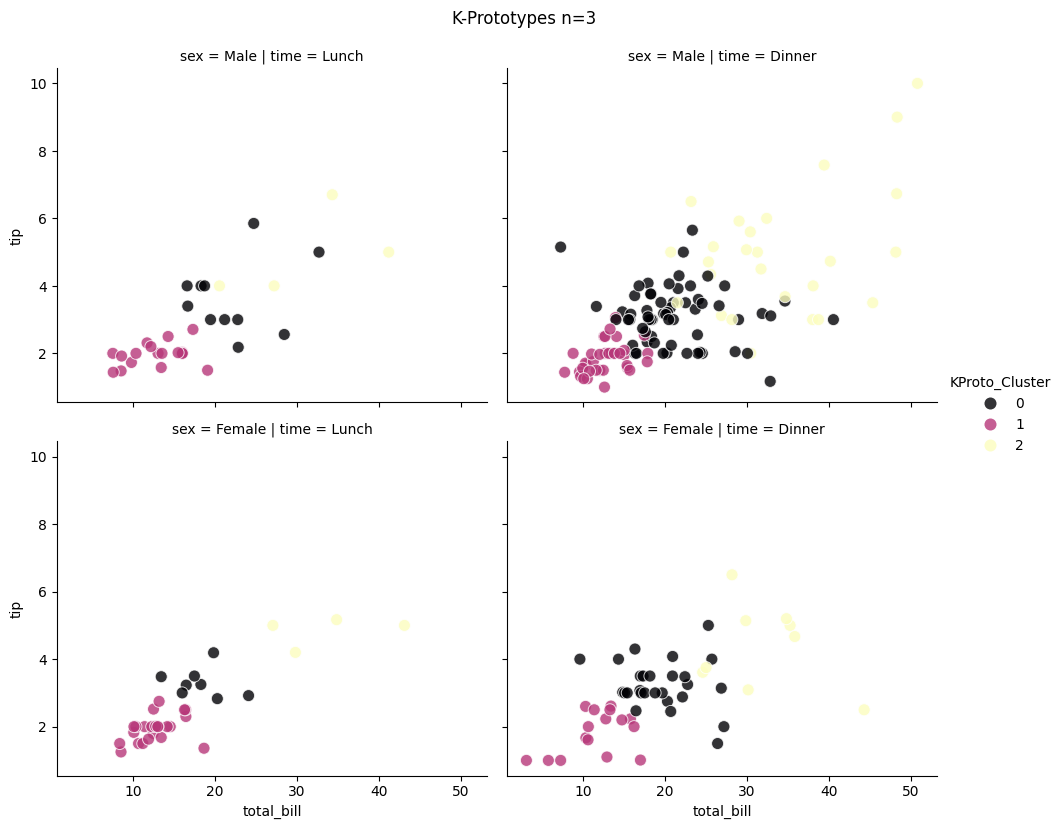

In [72]:

g = sns.relplot(
    data=tips, 
    x='total_bill', 
    y='tip', 
    hue='KProto_Cluster', 
    col='time', 
    row='sex',         # Physically splits the graph by Lunch vs Dinner
    palette='magma', 
    s=75, alpha=0.8,
    height=4, aspect=1.2
)

g.fig.suptitle("K-Prototypes n=3", y=1.03)
plt.show()

In each box, the algorithm uses a basic spending hierarchy: Black = Budget, Yellow = Standard, and Pink = Premium.

The algorithm treats a "Dinner" table differently from a "Lunch" table. For example, a $20 lunch bill might be marked "Standard," but a $20 dinner bill could be closer to "Budget" because the algorithm considers the meal type.

#### Gower Method

In [73]:
!pip install gower


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


To evaluate our mixed-data models, we first need to calculate the exact Gower distance between each pair of rows in our dataset. For this, we use the open-source `gower` package.

In [74]:
import gower

Modern libraries like Pandas use efficient `category` data types to save memory. However, older mathematical libraries such as `gower` and `numpy` do not recognise these types and will crash with a `TypeError`. We should remove the Pandas `category` formatting and convert those columns to standard Python strings (`object`).

In [75]:
for col in categorical_features:
    if tips_mixed[col].dtype.name == 'category':
        tips_mixed[col] = tips_mixed[col].astype('object')

In [76]:
tips_mixed

,total_bill,tip,size,sex,smoker,day,time
0,-0.314711,-1.439947,-0.600193,Female,No,Sun,Dinner
1,-1.063235,-0.969205,0.453383,Male,No,Sun,Dinner
2,0.137780,0.363356,0.453383,Male,No,Sun,Dinner
3,0.438315,0.225754,-0.600193,Male,No,Sun,Dinner
4,0.540745,0.443020,1.506958,Female,No,Sun,Dinner
...,...,...,...,...,...,...,...
239,1.040511,2.115963,0.453383,Male,No,Sat,Dinner
240,0.832275,-0.722971,-0.600193,Female,Yes,Sat,Dinner
241,0.324630,-0.722971,-0.600193,Male,Yes,Sat,Dinner
242,-0.221287,-0.904026,-0.600193,Male,No,Sat,Dinner


In [77]:
gower_dist_matrix = gower.gower_matrix(tips_mixed)
gower_dist_matrix

array([[0.        , 0.2016455 , 0.22298183, ..., 0.46128255, 0.299944  ,
        0.17980084],
       [0.2016455 , 0.        , 0.06113525, ..., 0.35657883, 0.19524029,
        0.3608114 ],
       [0.22298183, 0.06113525, 0.        , ..., 0.3430626 , 0.2087521 ,
        0.32889527],
       ...,
       [0.46128255, 0.35657883, 0.3430626 , ..., 0.        , 0.16133854,
        0.45608488],
       [0.299944  , 0.19524029, 0.2087521 , ..., 0.16133854, 0.        ,
        0.30842826],
       [0.17980084, 0.3608114 , 0.32889527, ..., 0.45608488, 0.30842826,
        0.        ]], shape=(244, 244), dtype=float32)

Take a close look at the Gower calculation output. We used a dataset with 244 rows, and the result is a (244, 244) matrix.

* Notice the zeros running diagonally through the array. For example, the first value is 0. This happens because the distance between Row 0 and itself is always zero.
* The algorithm calculated the exact distance between every receipt and every other one. That means it made 244 * 244 = 59,536 unique comparisons.
* With 244 rows, this calculation is fast. But if you had a real restaurant database with 1 million receipts, the matrix would need 1,000,000 * 1,000,000 calculations. That would use terabytes of RAM and could crash your computer. This shows why it’s important to consider the computational cost of our methods.

When you run a clustering model or calculate a Silhouette score in scikit-learn, it usually expects raw data coordinates, such as total_bill and tip. The library then works out the distances between these points as needed, almost always using the standard Euclidean straight-line method.

When we use `metric='precomputed'`, we let the function know that our data is already a complete N x N grid of distances.

In [78]:
def log_gower_clustering_metrics(gower_df, model_name, distance_matrix, labels):
    # Calculate Silhouette using the precomputed Gower N x N grid
    silhouette = round(silhouette_score(distance_matrix, labels, metric='precomputed'), 4)
    
  
    new_row = pd.DataFrame({
        'Mixed-Data Model': [model_name],
        'Gower Silhouette (Higher=Better,max 1)': [silhouette]
    })
    
    if gower_df is None or gower_df.empty:
        updated_gower_df = new_row
    else:
        updated_gower_df = pd.concat([gower_df, new_row], ignore_index=True)
        
    display(updated_gower_df)
    return updated_gower_df

In [79]:
gower_leaderboard = pd.DataFrame()

In [80]:
gower_leaderboard = log_gower_clustering_metrics(
    gower_leaderboard,
    'K-Prototypes',
    gower_dist_matrix, 
    tips['KProto_Cluster'] 
)

,Mixed-Data Model,"Gower Silhouette (Higher=Better,max 1)"
0,K-Prototypes,0.0794


K-Means produced a higher score by disregarding certain aspects of the data. In contrast, K-Prototypes yielded a lower score because it accounted for all relevant variables.

#### **Task 4**

## Hierrarchical clustering

In [81]:
from scipy.cluster.hierarchy import dendrogram, linkage

The **scipy.cluster.hierarchy.linkage function** performs hierarchical, agglomerative clustering by iteratively combining the closest clusters into a new one until only a single cluster remains. The result is a linkage matrix that encodes the cluster hierarchy and can be used to visualize a dendrogram. 

To decide how to merge clusters, the algorithm uses a linkage rule. The most common is Ward's Method, which merges clusters to minimise the increase in the total within-cluster variance at each step. 

But we cannot use Ward's Method because variance requires Euclidean geometry, and our data uses Gower distance with mixed types. So, we will use Average Linkage, which calculates the average Gower distance between all points in Cluster A and all points in Cluster B.

In [82]:
linked = linkage(gower_dist_matrix, method='average')

C:\Users\keiron.jones.TETRAD\AppData\Local\Temp\ipykernel_20212\1553030910.py:1: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linked = linkage(gower_dist_matrix, method='average')


A dendrogram shows the full history of every merge the algorithm performed.

* The Y-axis, or height, shows the Gower distance between two clusters when they merged. A tall vertical line means the algorithm joined two groups that were very different.
* To finish our model, we draw a horizontal line to cut across the vertical lines.
* The goal is to cut through the tallest vertical lines you can without crossing major intersections. Since the K-Means Elbow Method suggested 3 business tiers, we place our horizontal line at the highest point that gives us exactly 3 vertical branches.

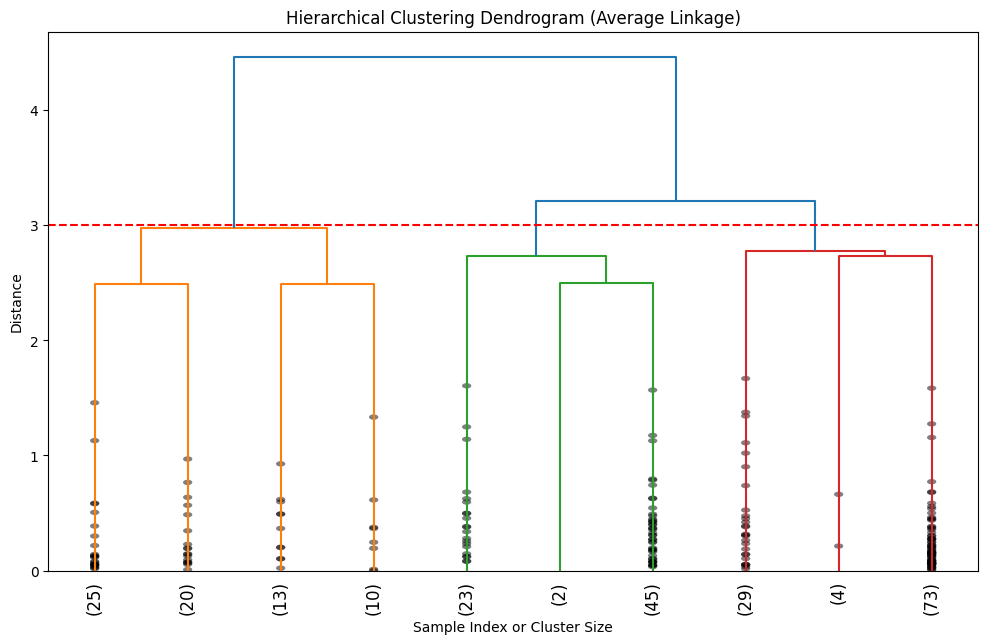

In [83]:
plt.figure(figsize=(12, 7))
dendrogram(linked,
           orientation='top',
           truncate_mode='lastp',
           p=10, # show only the last 10 merges
           show_leaf_counts=True,
           leaf_rotation=90.,
           leaf_font_size=12.,
           show_contracted=True,
)
plt.title('Hierarchical Clustering Dendrogram (Average Linkage)')
plt.xlabel('Sample Index or Cluster Size')
plt.ylabel('Distance')
plt.axhline(y=3, color='r', linestyle='--')


Documentation: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html

In [84]:
from sklearn.cluster import AgglomerativeClustering

In [85]:
agg_clustering = AgglomerativeClustering(n_clusters = 3, linkage='average', metric='precomputed')

# default n_clusters=2

In [86]:
agg_labels = agg_clustering.fit_predict(gower_dist_matrix)

In [87]:
agg_labels

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 0, 2, 2, 2, 2, 0, 0,
       0, 2, 0, 2, 0, 0, 2, 2, 0, 0, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 2, 0, 2, 2, 0, 2, 2, 2, 2, 0, 2, 2, 2, 2, 0, 2, 2, 2, 0, 2,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 2, 2, 0, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 2, 2, 2, 0, 0, 2, 0, 2, 2, 0, 0, 2, 2,
       0, 0])

In [88]:
gower_leaderboard = log_gower_clustering_metrics(
    gower_leaderboard,
    'Agglomerative Clustering (n=3, Average Linkage)',
    gower_dist_matrix, 
    agg_labels 
)

,Mixed-Data Model,"Gower Silhouette (Higher=Better,max 1)"
0,K-Prototypes,0.0794
1,"Agglomerative Clustering (n=3, Average Linkage)",0.4198


The downside of K-Prototypes is that it tries to create global, spherical boundaries around a central "prototype." Because mixed data is often messy and not spherical, global boundaries can lead to overlapping clusters and a low Silhouette score.

Agglomerative clustering doesn't rely on global shapes or centre points. With linkage='average', it looks for dense local groups of similar receipts and clusters them from the bottom up. 

In [89]:
tips['agg_clusters n=3'] = agg_labels

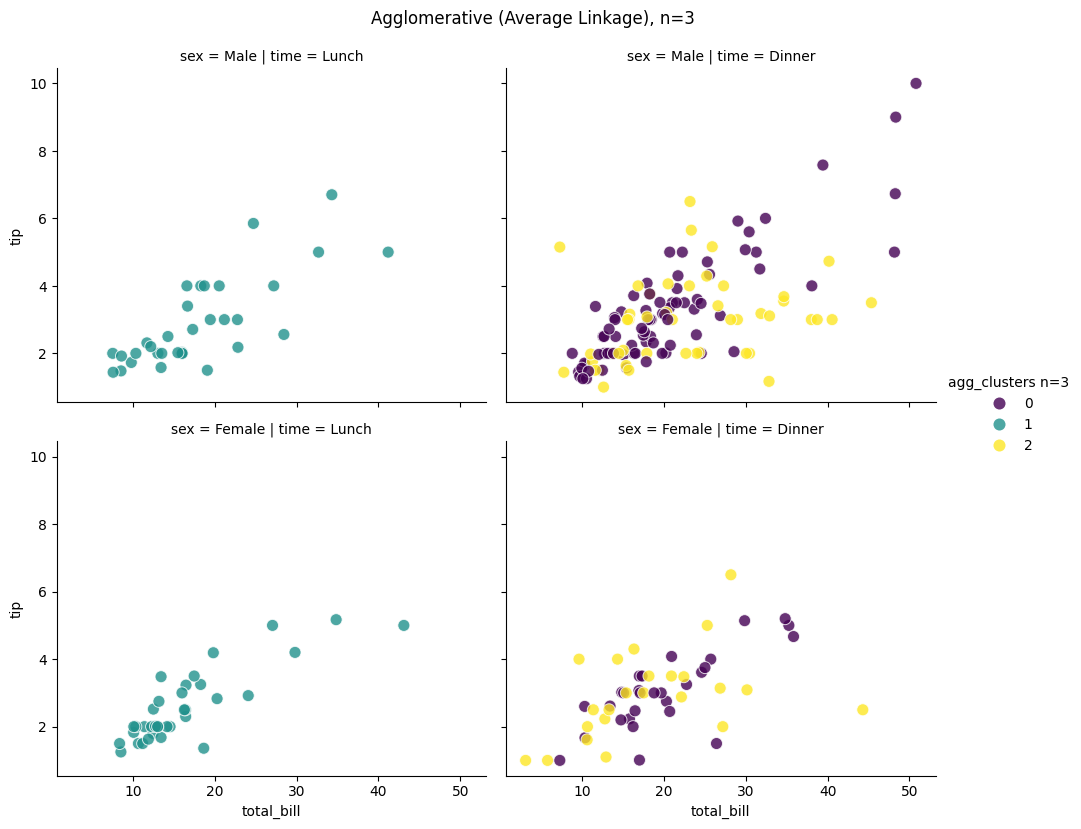

In [90]:
g = sns.relplot(
    data=tips, 
    x='total_bill', 
    y='tip', 
    hue='agg_clusters n=3', 
    col='time', 
    row='sex',
    palette='viridis', 
    s=75, alpha=0.8,
    height=4, aspect=1.2
)

g.fig.suptitle("Agglomerative (Average Linkage), n=3", y=1.03)
plt.show()

Cluster 1 (Teal) includes only Lunch, while Clusters 0 and 2 include only Dinner. The algorithm examined the Gower matrix and found that mixing Lunch and Dinner caused a major problem, so it avoided doing so. Instead, it first separated the restaurant data by Time of day, then divided the dinner group into high- and low-spenders.

#### **Task 5**

## DBSCAN Clustering

DBSCAN finds clusters based on density and does not require a pre-defined K. It requires tuning *eps* (neighborhood radius) and *min_samples*.


With density algorithms, we need to identify the precise point where our data separates. For our approach, a neighbourhood had to include at least 10 receipts within a 15% dissimilarity radius to count as a valid cluster. If a table couldn’t find 9 very similar neighbours, we removed it from the model as an outlier.

In [108]:
dbscan_eps = 0.15
dbscan_min_samples = 10

In [109]:
from sklearn.cluster import DBSCAN

In [110]:
dbscan = DBSCAN(eps=dbscan_eps, min_samples=dbscan_min_samples, metric='precomputed')

dbscan_labels = dbscan.fit_predict(gower_dist_matrix)

In [111]:
dbscan_labels

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1, -1,  0, -1, -1, -1, -1, -1,  0,  0,  0,  0, -1,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,
       -1,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0, -1,
        0,  0,  0,  0,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1,
        1,  1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,
       -1, -1, -1,  1, -1

Labels of -1 indicate noise/outliers.

In [112]:
tips['DBSCAN_Mixed_Cluster'] = dbscan_labels

In [113]:
if -1 in dbscan_labels:
    valid_indices = dbscan_labels != -1
    outlier_indices = dbscan_labels == -1
    X_outliers = tips[outlier_indices]
    X_eval = tips[valid_indices]
    labels_eval = dbscan_labels[valid_indices]

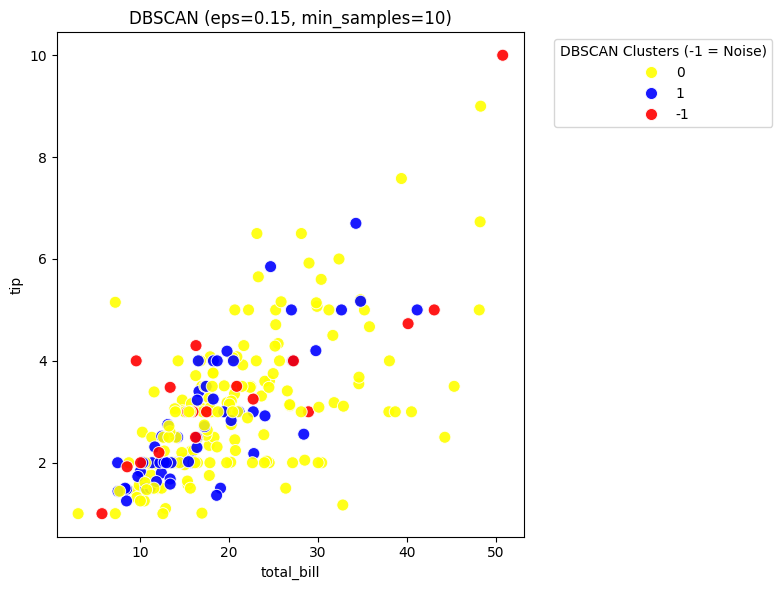

In [122]:
dbscan_palette = {'-1': 'red', '0': 'yellow', '1': 'blue'}

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=tips, 
    x='total_bill', 
    y='tip', 
    hue=tips['DBSCAN_Mixed_Cluster'].astype(str), 
    palette=dbscan_palette,
    s=75, alpha=0.9
)

plt.legend(title='DBSCAN Clusters (-1 = Noise)', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title(f"DBSCAN (eps={dbscan_eps}, min_samples={dbscan_min_samples})")
plt.tight_layout()
plt.show()

In [115]:
gower_leaderboard = log_gower_clustering_metrics(
    gower_leaderboard,
    'DBSCAN eps=0.15, min_samples=10',
    gower_dist_matrix, 
    dbscan_labels 
)

,Mixed-Data Model,"Gower Silhouette (Higher=Better,max 1)"
0,K-Prototypes,0.0794
1,"Agglomerative Clustering (n=3, Average Linkage)",0.4198
2,"DBSCAN eps=0.15, min_samples=10",0.3626
3,"DBSCAN eps=0.15, min_samples=10",0.3626


#### **Task 6**

**Conclusion**

* If you need strict operational tiers, use K-Means.

* If you need pure persona profiles, use K-Modes.

* If you need a unified compromise, use K-Prototypes.

* If you need to aggressively segregate by category, use Agglomerative.

* If you need to find the main cluster and leave out unusual outliers, use DBSCAN.
